# Machine Learning — Lab 3: Linear Regression with Python

This notebook is the practical workspace for Lab 3. Follow the lab sheet for the activity sequence and all written-answer questions.

**Dataset:** scikit-learn diabetes dataset  
**Main idea:** Do not start by assuming linear regression. First inspect the prediction target and the feature behaviour, then test whether a linear model is a useful baseline.


### How to complete the notebook

In each **TODO** code cell, the required Python code is already provided but **commented out**.

1. Read the code and connect it with the concept demonstrated in class.
2. Remove the `#` from the provided code lines.
3. Run the cell and inspect the output or plot.
4. Continue to the next TODO only after you understand the result.

The written-answer questions are in the **Lab Sheet**, not in this notebook.


## Part A — Understand the prediction problem
Inspect the dataset and target before deciding what kind of supervised learning problem you have.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
diabetes = load_diabetes()
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [3]:

sns.set_theme(style="whitegrid")

# Load the built-in dataset
# Load the built-in diabetes dataset
X, y = load_diabetes(return_X_y=True, as_frame=True)

# Create one DataFrame containing features and target
df = X.copy()
df["target"] = y

print("Dataset loaded successfully")
print("Number of observations:", len(df))
print("Number of input features:", X.shape[1])




Dataset loaded successfully
Number of observations: 442
Number of input features: 10


In [4]:
# TODO 1: Display the first five rows of the complete DataFrame.
# Uncomment the code below and run the cell.

first_rows = df.head()
first_rows


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [6]:
# TODO 2: Display the dataset shape and summary statistics.
# Uncomment the code below and run the cell.

print("Shape:", df.shape)
summary = df.describe()
summary


Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


## Part B — Explore whether a linear model is reasonable to try
Use the target distribution, feature-versus-target plots and correlations as pre-model evidence.

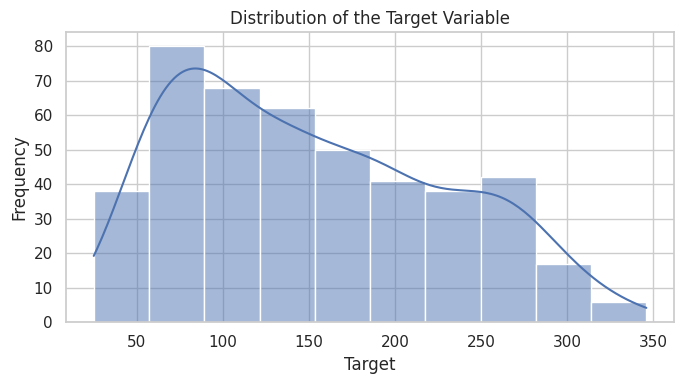

In [7]:
# TODO 3: Plot the distribution of the target variable.
# Uncomment the code below and run the cell.

plt.figure(figsize=(7, 4))
sns.histplot(df["target"], kde=True)
plt.title("Distribution of the Target Variable")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


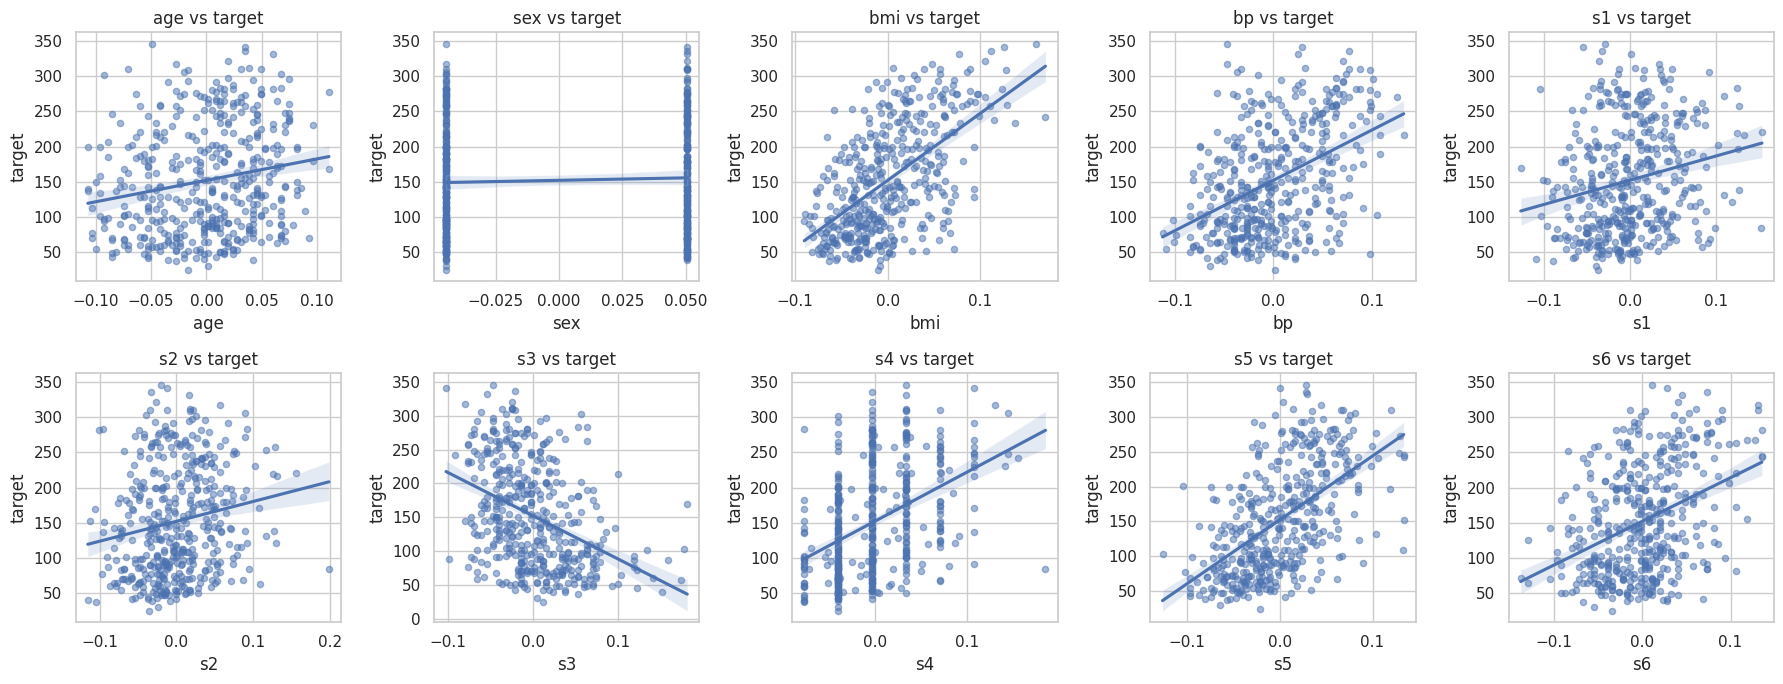

In [8]:
# TODO 4: Plot every input feature against the target.
# Create one regression plot per feature in a 2 x 5 grid.
# Uncomment the code below and run the cell.

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

for feature, ax in zip(X.columns, axes):
    sns.regplot(data=df, x=feature, y="target", ax=ax,
                scatter_kws={"alpha": 0.5, "s": 20})
    ax.set_title(f"{feature} vs target")

plt.tight_layout()
plt.show()


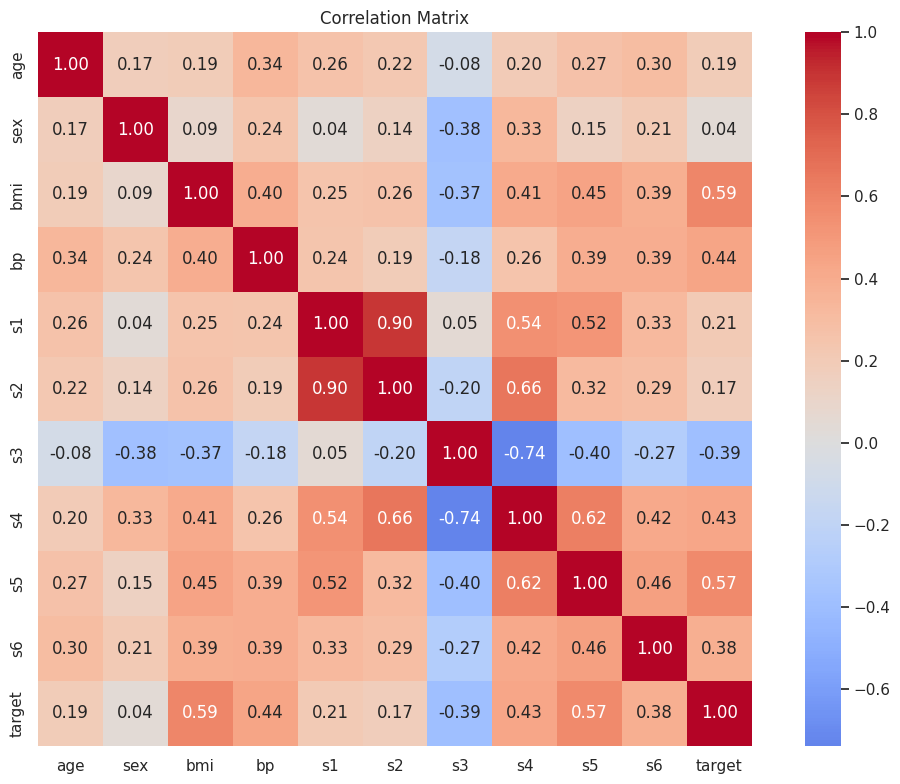

In [9]:
# TODO 5: Compute the correlation matrix and plot a heatmap.
# Include all 10 input features and the target.
# Uncomment the code below and run the cell.

corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


In [10]:
# Run this after completing TODO 5.
# Rank the input features by the absolute size of their correlation with the target.

target_correlations = (
    corr_matrix["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)
target_correlations.to_frame("correlation_with_target")

,correlation_with_target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


## Part C — Create the train/test split and a naive baseline
A baseline gives us a reference point. Here it predicts the mean training target for every test observation.

In [11]:
# TODO 6: Split the data into training and testing sets.
# Use 80% for training, 20% for testing, and random_state=42.
# Uncomment the code below and run the cell.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 353
Testing samples: 89


In [12]:
# TODO 7: Build the mean-prediction baseline using DummyRegressor.
# Use strategy='mean', fit it on the training data, and predict the test set.
# Uncomment the code below and run the cell.

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline RMSE: {baseline_rmse:.3f}")
print(f"Baseline R^2 : {baseline_r2:.3f}")


Baseline RMSE: 73.222
Baseline R^2 : -0.012


## Part D — Build multiple linear regression using all features
Do not select only the strongly correlated features. Use all ten input features for this model.

In [21]:
# TODO 8: Create, train and use the multiple linear regression model.
# Use ALL input features.
# Uncomment the code below and run the cell.

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


In [20]:
# TODO 9: Calculate MSE, RMSE and R-squared for linear regression.
# Uncomment the code below and run the cell.

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression MSE : {mse:.3f}")
print(f"Linear Regression RMSE: {rmse:.3f}")
print(f"Linear Regression R^2 : {r2:.3f}")
print("\nImprovement in RMSE over baseline:", baseline_rmse - rmse)


Linear Regression MSE : 2900.194
Linear Regression RMSE: 53.853
Linear Regression R^2 : 0.453

Improvement in RMSE over baseline: 19.36904700005651


In [19]:
# Compare the two models in one small table.
comparison = pd.DataFrame({
    "Model": ["Mean baseline", "Linear regression"],
    "RMSE": [baseline_rmse, rmse],
    "R_squared": [baseline_r2, r2]
})
comparison

,Model,RMSE,R_squared
0,Mean baseline,73.222493,-0.011963
1,Linear regression,53.853446,0.452603


## Part E — Diagnose the fitted linear model
Now use post-model evidence to judge how well the linear form behaves.

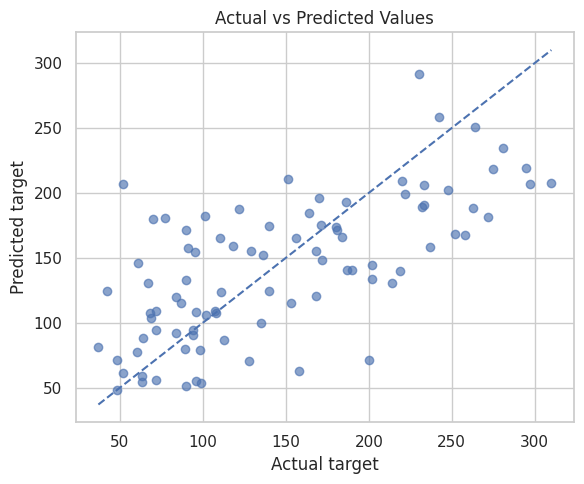

In [16]:
# TODO 10: Plot actual values against predicted values.
# The diagonal y = x line represents perfect predictions.
# Uncomment the code below and run the cell.

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.65)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual vs Predicted Values")
plt.tight_layout()
plt.show()


In [ ]:
# TODO 11: Compute residuals and plot residuals against predictions.
# Residual = actual value - predicted value.
# Uncomment the code below and run the cell.

residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted target")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()


## Part F — Inspect model coefficients

In [18]:
# TODO 12: Create a coefficient table.
# Include Feature, Coefficient and Absolute_Coefficient.
# Sort from largest to smallest Absolute_Coefficient.
# Uncomment the code below and run the cell.

coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
coefficient_table["Absolute_Coefficient"] = coefficient_table["Coefficient"].abs()
coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient", ascending=False
)
coefficient_table


,Feature,Coefficient,Absolute_Coefficient
4,s1,-931.488846,931.488846
8,s5,736.198859,736.198859
2,bmi,542.428759,542.428759
5,s2,518.062277,518.062277
3,bp,347.703844,347.703844
7,s4,275.317902,275.317902
1,sex,-241.964362,241.964362
6,s3,163.419983,163.419983
9,s6,48.670657,48.670657
0,age,37.904021,37.904021


## Part G — Use the trained model for an unseen observation
The test set was not used to fit the model, so a test row can demonstrate how the trained model is used for inference.

In [17]:
# Final practical step: USE the trained model on one unseen observation.
# Change sample_position to try another test observation.
# Uncomment the code below and run the cell.

sample_position = 0
new_sample = X_test.iloc[[sample_position]]

predicted_value = model.predict(new_sample)[0]
actual_value = y_test.iloc[sample_position]

print("Input features for the unseen observation:")
display(new_sample)
print(f"Predicted target: {predicted_value:.2f}")
print(f"Actual target   : {actual_value:.2f}")
print(f"Absolute error  : {abs(actual_value - predicted_value):.2f}")


Input features for the unseen observation:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
287,0.045341,-0.044642,-0.006206,-0.015999,0.125019,0.125198,0.019187,0.034309,0.032432,-0.00522


Predicted target: 139.55
Actual target   : 219.00
Absolute error  : 79.45


## Finish
Save the completed notebook using your registration number as part of the filename. All written questions are in the lab sheet, not in this notebook.